<a href="https://colab.research.google.com/github/Shanmukh5922/Exploratory_data_analysis/blob/main/25BAI0140_EXP7_25.08.2026/Iris_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
iris_df = pd.read_csv('/content/Iris.csv')

# Display the first 5 rows of the DataFrame
display(iris_df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
# Display basic information about the dataset
print(iris_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


In [3]:
# Display descriptive statistics
display(iris_df.describe())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


The dataset contains 150 entries with 5 columns: 'Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', and 'PetalWidthCm', and 'Species'. There are no missing values, and the data types are appropriate. The 'Id' column seems to be just an identifier and might not be useful for analysis. The 'Species' column is categorical, and the rest are numerical.

In [4]:
# Drop the 'Id' column as it is just an identifier and not useful for analysis
iris_df = iris_df.drop('Id', axis=1)

# Display the first 5 rows of the DataFrame after dropping 'Id'
display(iris_df.head())

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Now, let's create a pair plot to visualize the relationships between all numerical features, colored by the 'Species' column. This will give us a comprehensive overview of how the different iris species vary across the sepal and petal measurements.

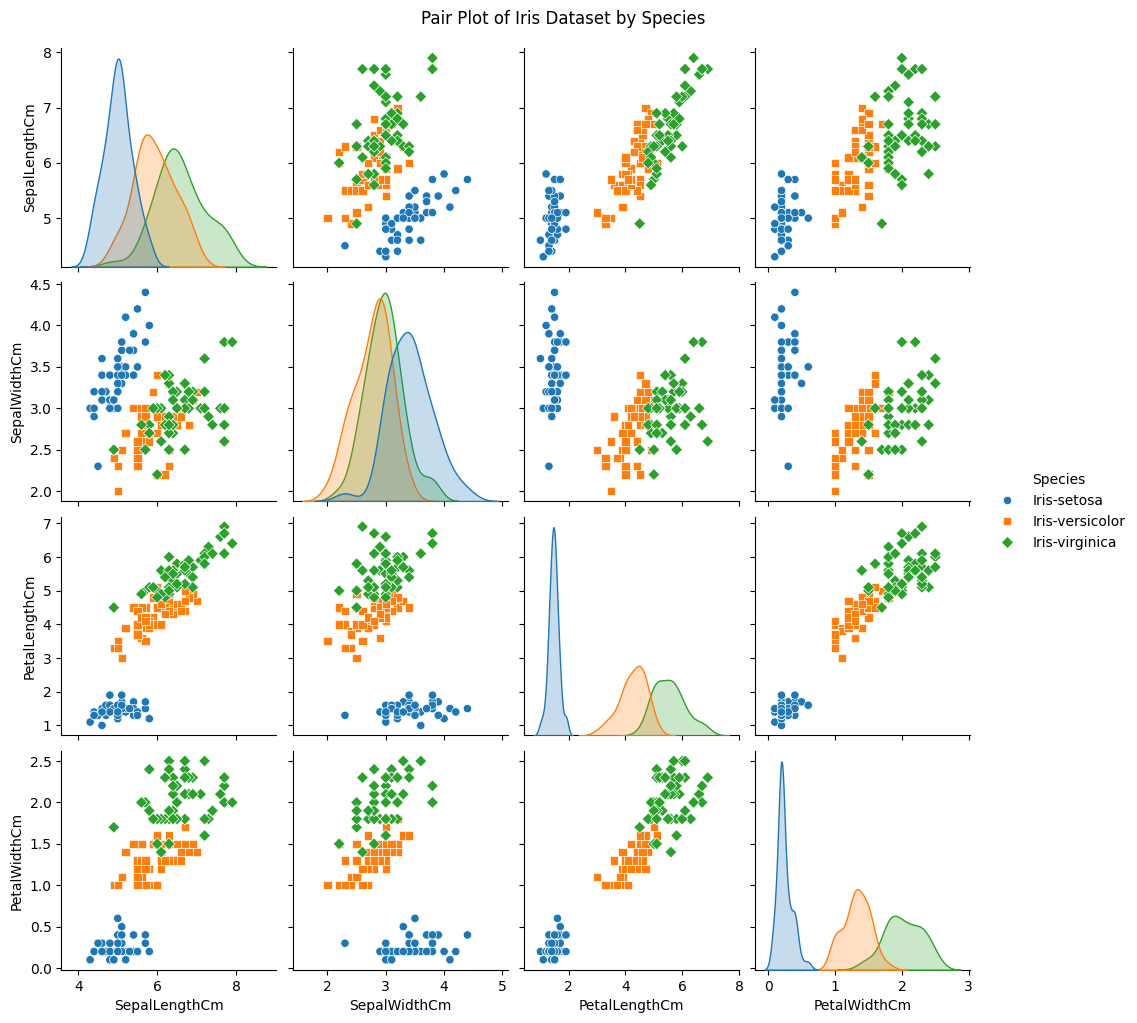

In [5]:
# Create a pair plot to visualize relationships between features, colored by species
sns.pairplot(iris_df, hue='Species', markers=['o', 's', 'D'])
plt.suptitle('Pair Plot of Iris Dataset by Species', y=1.02) # Add a title above the subplots
plt.show()

The pair plot reveals clear distinctions between the species. Iris-setosa is well-separated from the other two species in all feature pairs. Iris-versicolor and Iris-virginica show more overlap, particularly in sepal measurements, but are more distinguishable based on petal length and width. Petal length and petal width appear to be the most discriminating features for classifying iris species.

Now, let's create violin plots for each numerical feature to visualize their distributions across the different iris species. This will provide more detailed insights into the spread and density of each measurement for each species.

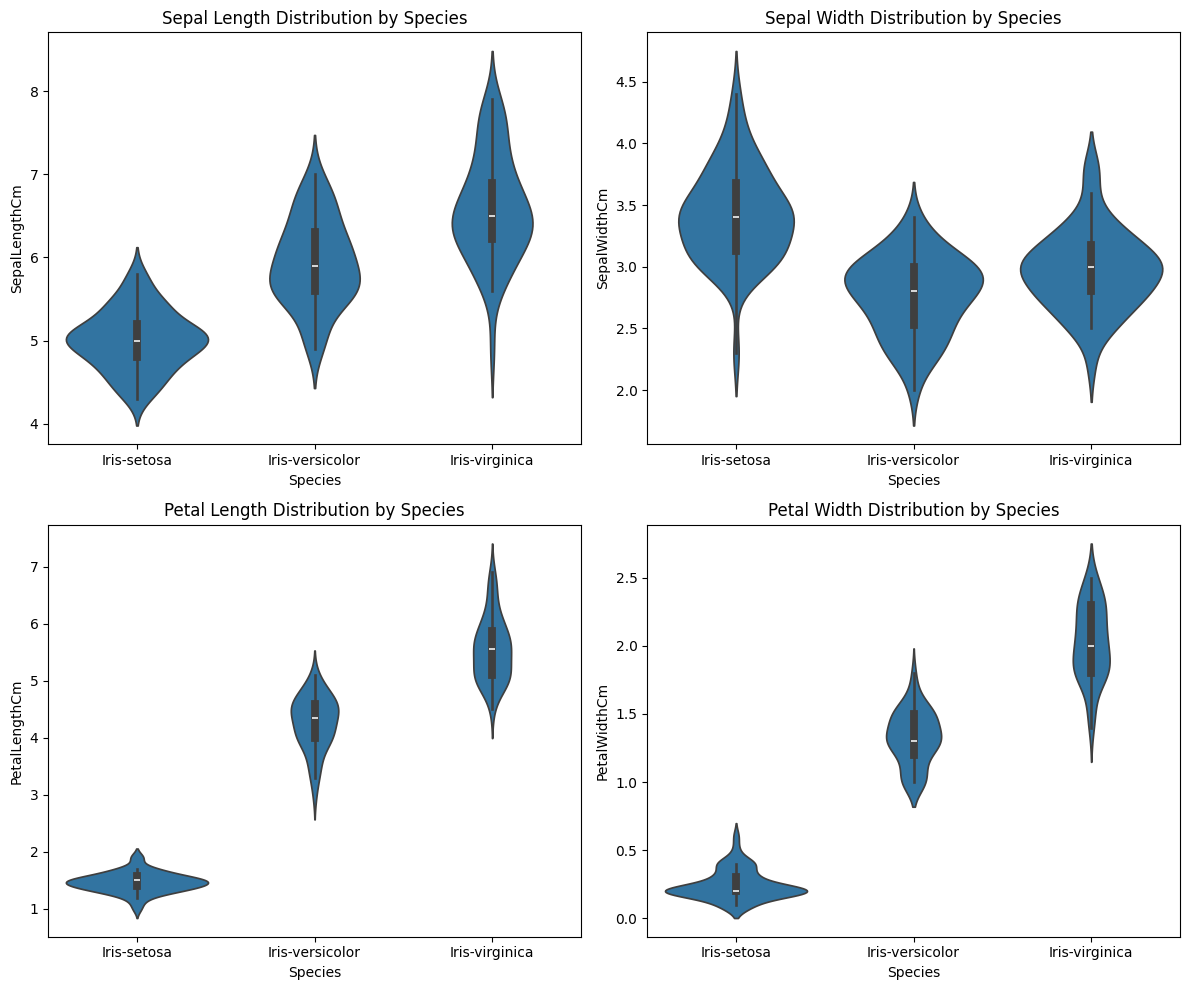

In [6]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
sns.violinplot(x='Species', y='SepalLengthCm', data=iris_df)
plt.title('Sepal Length Distribution by Species')

plt.subplot(2, 2, 2)
sns.violinplot(x='Species', y='SepalWidthCm', data=iris_df)
plt.title('Sepal Width Distribution by Species')

plt.subplot(2, 2, 3)
sns.violinplot(x='Species', y='PetalLengthCm', data=iris_df)
plt.title('Petal Length Distribution by Species')

plt.subplot(2, 2, 4)
sns.violinplot(x='Species', y='PetalWidthCm', data=iris_df)
plt.title('Petal Width Distribution by Species')

plt.tight_layout()
plt.show()

The violin plots confirm the observations from the pair plot. Iris-setosa is clearly distinguishable by its smaller petal length and width, and generally larger sepal width. Iris-versicolor and Iris-virginica show some overlap, particularly in sepal measurements, but their petal length and width distributions are largely distinct, with Iris-virginica having larger petals on average.

Let's compute the correlation matrix for the numerical features and visualize it using a heatmap to understand the linear relationships between them.

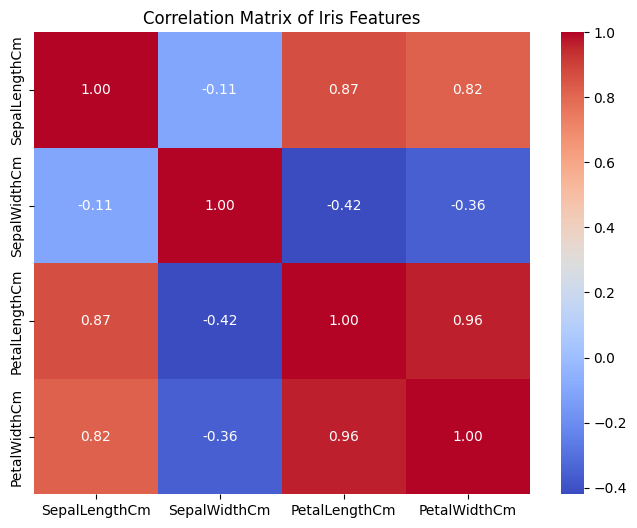

In [7]:
# Calculate the correlation matrix
correlation_matrix = iris_df.drop('Species', axis=1).corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Iris Features')
plt.show()

The correlation matrix heatmap shows strong positive correlations between `PetalLengthCm` and `PetalWidthCm`, and also between `SepalLengthCm` and `PetalLengthCm`/`PetalWidthCm`. `SepalWidthCm` shows a negative correlation with `PetalLengthCm` and `PetalWidthCm`, and a weaker positive correlation with `SepalLengthCm`. This confirms that petal dimensions are highly related and are good indicators for distinguishing species.

Let's further visualize the distribution of each feature using histograms with Kernel Density Estimates (KDE), separated by species. This will highlight the individual feature ranges and densities for each Iris species.

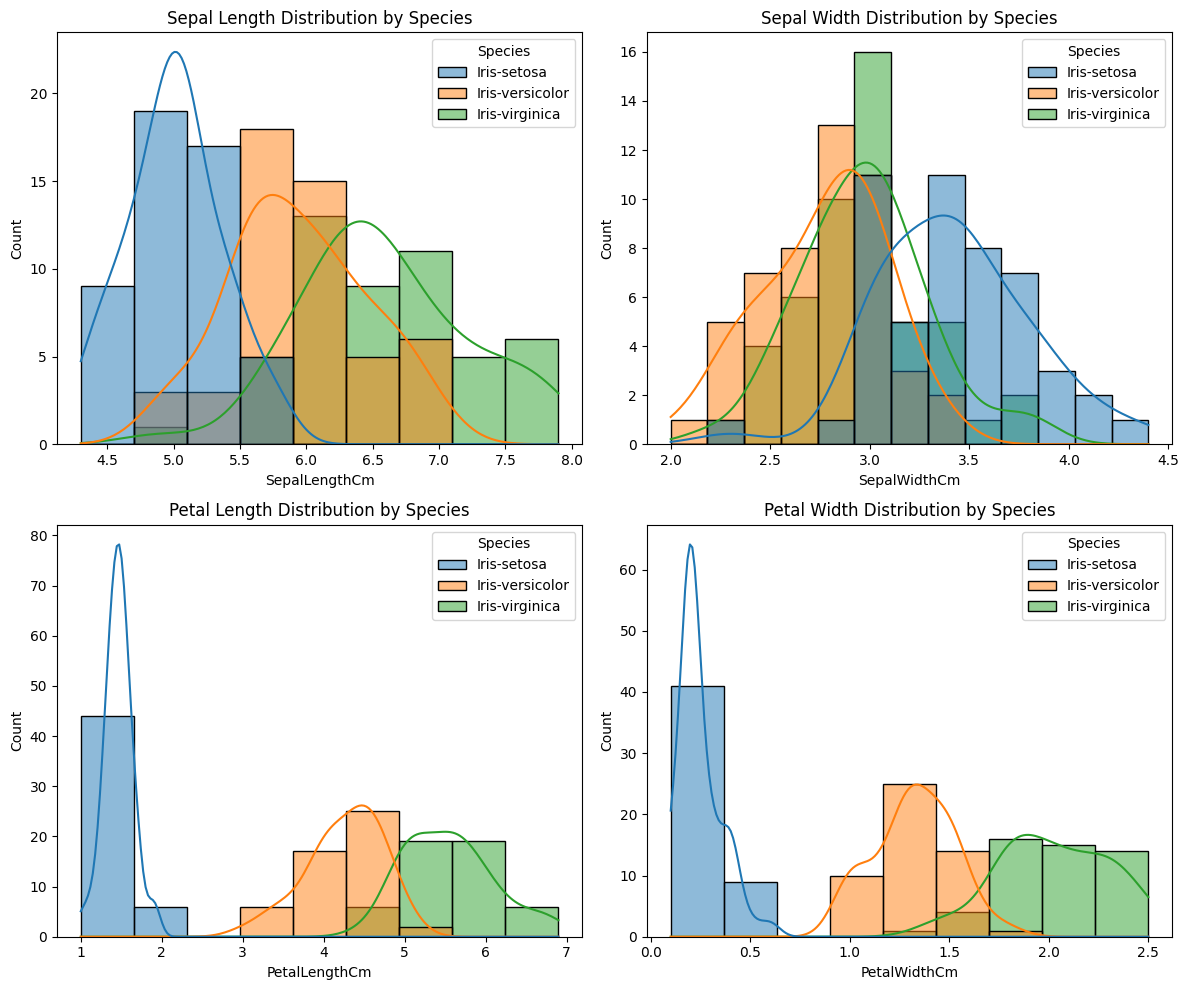

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(data=iris_df, x='SepalLengthCm', hue='Species', kde=True, ax=axes[0,0])
axes[0,0].set_title('Sepal Length Distribution by Species')

sns.histplot(data=iris_df, x='SepalWidthCm', hue='Species', kde=True, ax=axes[0,1])
axes[0,1].set_title('Sepal Width Distribution by Species')

sns.histplot(data=iris_df, x='PetalLengthCm', hue='Species', kde=True, ax=axes[1,0])
axes[1,0].set_title('Petal Length Distribution by Species')

sns.histplot(data=iris_df, x='PetalWidthCm', hue='Species', kde=True, ax=axes[1,1])
axes[1,1].set_title('Petal Width Distribution by Species')

plt.tight_layout()
plt.show()

These histograms with KDEs provide a clear visual of the unimodal or bimodal distributions of each feature for each species. They reaffirm that Petal Length and Petal Width show distinct, largely non-overlapping distributions for the different species, making them excellent features for classification. Sepal Length also shows good separation, while Sepal Width has more overlap between species.

Let's now visualize the distribution of each feature across the different species using box plots. Box plots are great for showing the five-number summary (minimum, first quartile, median, third quartile, and maximum) and potential outliers.

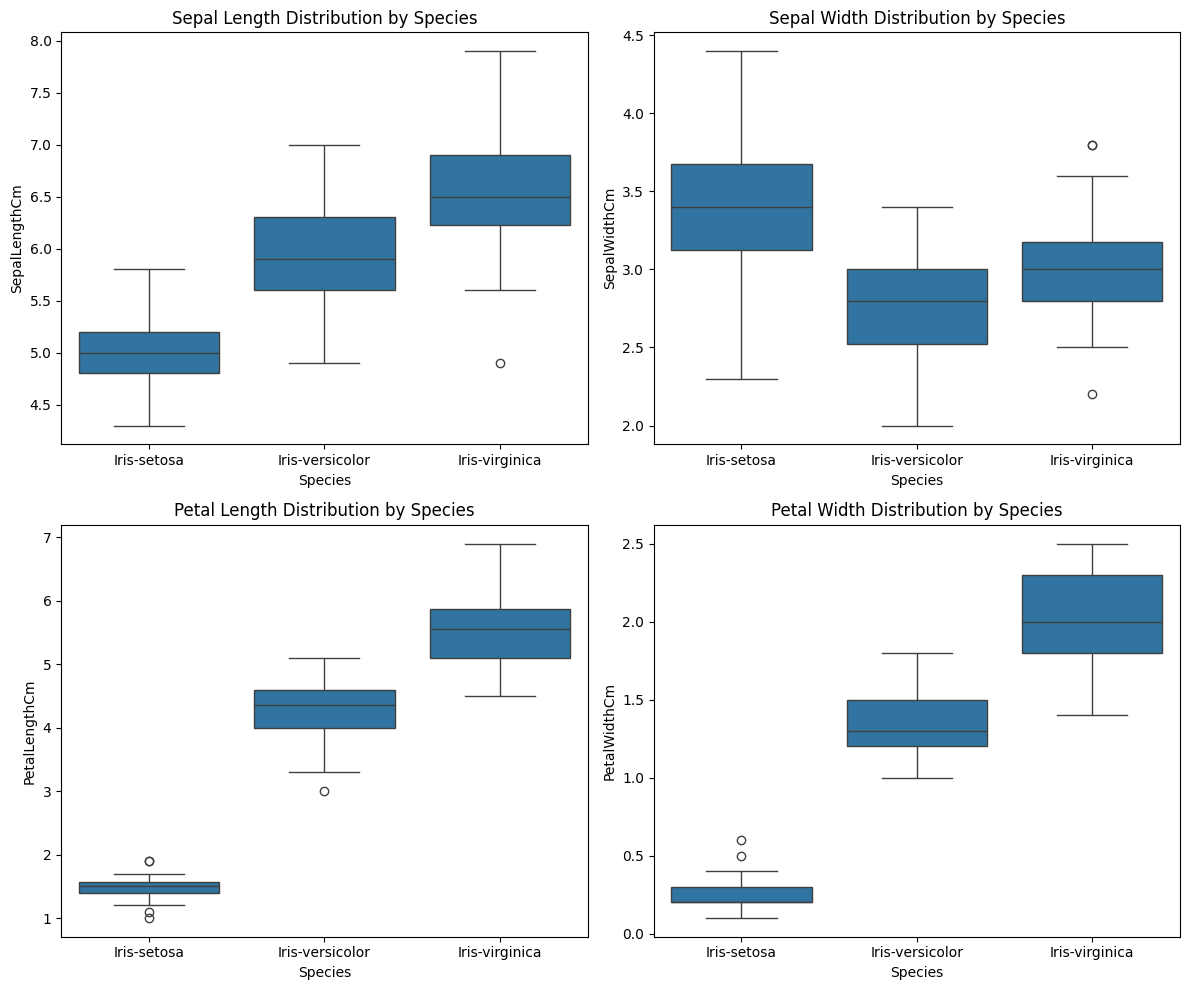

In [9]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
sns.boxplot(x='Species', y='SepalLengthCm', data=iris_df)
plt.title('Sepal Length Distribution by Species')

plt.subplot(2, 2, 2)
sns.boxplot(x='Species', y='SepalWidthCm', data=iris_df)
plt.title('Sepal Width Distribution by Species')

plt.subplot(2, 2, 3)
sns.boxplot(x='Species', y='PetalLengthCm', data=iris_df)
plt.title('Petal Length Distribution by Species')

plt.subplot(2, 2, 4)
sns.boxplot(x='Species', y='PetalWidthCm', data=iris_df)
plt.title('Petal Width Distribution by Species')

plt.tight_layout()
plt.show()

The box plots visually confirm the insights gained from the violin plots and histograms. Iris-setosa is consistently distinct, especially in petal measurements, with very little overlap. Iris-versicolor and Iris-virginica show some overlap in sepal dimensions but are generally well-separated by petal length and width. We can also observe potential outliers, particularly in the SepalWidthCm for Iris-setosa and Iris-versicolor.